# Metrical BDI: evaluation and calibration — hexameter corpus

This notebook evaluates and calibrates the metrical Bootstrap Distance Imposters (BDI) procedure on texts of known authorship in the hexameter corpus.

The four texts to be attributed are complete holdouts and do not contribute to scaling or calibration:

- `X_ordine`
- `X2_ecclesiastes`
- `X3_machabeis`
- `X4_certamina`

The metrical representation and BDI settings are the same as in the original application notebooks:

- metrical features already contained in `output.csv`;
- `minmax` / Ružička distance;
- 1000 bootstrap iterations;
- `rnd_prop = 0.5`.

Calibration consists of 800 known-authorship verification problems:

- 400 same-author comparisons;
- 400 different-author comparisons.

For every calibration problem, the query segment is removed from the comparison corpus before BDI is fitted. A logistic regression then converts BDI match strength into a corpus-specific probability of same authorship.

The classification measures reported below refer to the calibration sample itself, as in the lexical-analysis workflow.


In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

import joblib

from bdi import BDIVerifier

logging.basicConfig(level="WARNING")


## Paths and input corpus

In [4]:
def find_metrical_root():
    current = Path.cwd().resolve()

    for folder in [current, *current.parents]:
        if (folder / "output.csv").is_file():
            return folder

    raise FileNotFoundError(
        "Could not find the Metrical analysis root containing output.csv."
    )


BASE_DIR = find_metrical_root()
CORPUS_PATH = BASE_DIR / "output.csv"

print(f"Metrical analysis root: {BASE_DIR}")
print(f"Input corpus:           {CORPUS_PATH}")


Metrical analysis root: /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/hexameters/Metrical analysis
Input corpus:           /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/hexameters/Metrical analysis/output.csv


In [5]:
raw_df = pd.read_csv(CORPUS_PATH, encoding="utf-8")

print(f"Loaded {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
print(f"Authors/codes: {sorted(raw_df['Author'].astype(str).unique())}")
print()

display(
    raw_df.groupby(["Author", "Work"])
    .size()
    .rename("n_segments")
    .reset_index()
)


Loaded 663 rows, 24 columns
Authors/codes: ['AI', 'AeC', 'AeP', 'B', 'BC', 'DC', 'E', 'FB', 'GAp', 'GAr', 'GC', 'GM', 'GP', 'GVS', 'GiP', 'H', 'HA', 'HP', 'IH', 'II', 'M', 'NLC', 'OM', 'OSE', 'RC', 'RT', 'SG', 'U1', 'U10', 'U11', 'U2', 'U3', 'U4', 'U5', 'U6', 'U7', 'U8', 'U9', 'X', 'X2', 'X3', 'X4']



,Author,Work,n_segments
0,AI,anticlaudianus,29
1,AeC,medicaminum,29
2,AeC,viaticus,15
3,AeP,karolinus,16
4,B,judas,5
5,BC,contemptu,19
6,DC,mathildis,18
7,E,biblia,9
8,FB,nuptis,30
9,GAp,roberti,18


## Holdouts

The four attribution problems remain in `output.csv` so that the application notebooks can use them later, but none of them contributes to scaling, BDI calibration or logistic calibration.


In [7]:
HOLDOUT_AUTHORS = {"X", "X2", "X3", "X4"}

holdout_mask = raw_df["Author"].astype(str).isin(HOLDOUT_AUTHORS)
known_mask = ~holdout_mask

known_df = raw_df.loc[known_mask].copy()
holdout_df = raw_df.loc[holdout_mask].copy()

print(f"Known-author segments: {len(known_df)}")
print(f"Holdout segments:      {len(holdout_df)}")

print("\nHoldouts:")
display(
    holdout_df.groupby(["Author", "Work"])
    .size()
    .rename("n_segments")
    .reset_index()
)

expected = {
    ("X", "ordine"),
    ("X2", "ecclesiastes"),
    ("X3", "machabeis"),
    ("X4", "certamina"),
}

found = set(
    holdout_df[["Author", "Work"]]
    .astype(str)
    .itertuples(index=False, name=None)
)

missing = expected - found
if missing:
    print(f"WARNING: expected holdout pairs not found: {sorted(missing)}")


Known-author segments: 655
Holdout segments:      8

Holdouts:


,Author,Work,n_segments
0,X,ordine,3
1,X2,ecclesiastes,1
2,X3,machabeis,3
3,X4,certamina,1


## Labels and scaling

In [9]:
label_encoder = LabelEncoder()
known_df["author_label"] = label_encoder.fit_transform(
    known_df["Author"].astype(str)
)

mapping = (
    known_df[["Author", "author_label"]]
    .drop_duplicates()
    .sort_values("author_label")
)

print("Known-author label mapping:")
print(mapping.to_string(index=False))

joblib.dump(
    label_encoder,
    BASE_DIR / "metrical_label_encoder.pkl",
)


Known-author label mapping:
Author  author_label
    AI             0
   AeC             1
   AeP             2
     B             3
    BC             4
    DC             5
     E             6
    FB             7
   GAp             8
   GAr             9
    GC            10
    GM            11
    GP            12
   GVS            13
   GiP            14
     H            15
    HA            16
    HP            17
    IH            18
    II            19
     M            20
   NLC            21
    OM            22
   OSE            23
    RC            24
    RT            25
    SG            26
    U1            27
   U10            28
   U11            29
    U2            30
    U3            31
    U4            32
    U5            33
    U6            34
    U7            35
    U8            36
    U9            37


['/Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/hexameters/Metrical analysis/metrical_label_encoder.pkl']

In [10]:
# Same numeric feature set as in the original BDI notebooks.
numeric_cols = raw_df.select_dtypes(include=["number"]).columns.tolist()

if not numeric_cols:
    raise ValueError("No numeric metrical features found in output.csv.")

scaler = StandardScaler(with_mean=False)
scaler.fit(known_df[numeric_cols])

known_scaled = pd.DataFrame(
    scaler.transform(known_df[numeric_cols]),
    columns=numeric_cols,
    index=known_df.index,
)

known_scaled["author_label"] = known_df["author_label"].values

joblib.dump(
    scaler,
    BASE_DIR / "metrical_scaler.pkl",
)

print(f"Numeric metrical features: {len(numeric_cols)}")
print(f"Scaler fitted on {len(known_df)} known-author segments only.")
print("Holdout segments used for scaler fitting: 0")


Numeric metrical features: 21
Scaler fitted on 655 known-author segments only.
Holdout segments used for scaler fitting: 0


## BDI calibration

The query segment is held out from the comparison corpus in every calibration problem.

Authors represented by only one segment cannot provide a same-author query because removing that segment would leave no comparison segment for the candidate. They remain available as impostors and as candidates in different-author problems.


In [12]:
N_SAME = 400
N_DIFFERENT = 400

N_BOOTSTRAP = 1000
RND_PROP = 0.5

CALIBRATION_SEED = 42
master_rng = np.random.default_rng(CALIBRATION_SEED)

author_counts = known_df["author_label"].value_counts()

same_valid_labels = set(
    author_counts[author_counts >= 2].index
)

same_valid_indices = known_df.index[
    known_df["author_label"].isin(same_valid_labels)
].to_numpy(copy=True)

all_known_indices = known_df.index.to_numpy(copy=True)
all_known_labels = sorted(known_df["author_label"].unique())

print(f"Known authors: {len(all_known_labels)}")
print(f"Known segments: {len(all_known_indices)}")
print(
    "Authors eligible to provide same-author Q: "
    f"{len(same_valid_labels)}"
)

if len(same_valid_indices) == 0:
    raise ValueError(
        "No author has at least two known segments; "
        "same-author calibration cannot be performed."
    )


Known authors: 38
Known segments: 655
Authors eligible to provide same-author Q: 37


In [13]:
def run_metric_bdi_case(
    q_index: int,
    candidate_label: int,
    seed: int,
) -> float:
    """Run one leave-one-segment-out metrical BDI verification problem."""

    pool_indices = known_df.index[known_df.index != q_index]

    pool_X = known_scaled.loc[
        pool_indices,
        numeric_cols,
    ].to_numpy()

    pool_y = known_df.loc[
        pool_indices,
        "author_label",
    ].to_numpy()

    q_X = known_scaled.loc[
        [q_index],
        numeric_cols,
    ].to_numpy()

    if candidate_label not in set(pool_y):
        raise ValueError(
            f"Candidate label {candidate_label} has no comparison segment "
            f"after holding out Q={q_index}."
        )

    verifier = BDIVerifier(
        metric="minmax",
        nb_bootstrap_iter=N_BOOTSTRAP,
        rnd_prop=RND_PROP,
        random_state=np.random.default_rng(seed),
    )

    verifier.fit(pool_X, pool_y)

    score = verifier.predict_proba(
        q_X,
        [candidate_label],
    )

    return float(np.asarray(score).reshape(-1)[0])


In [14]:
calibration_rows = []

# ---------------------------------------------------------
# 400 SAME-AUTHOR problems
# ---------------------------------------------------------
same_q_indices = master_rng.choice(
    same_valid_indices,
    size=N_SAME,
    replace=True,
)

for q_index in tqdm(
    same_q_indices,
    desc="Same-author calibration",
):
    q_label = int(known_df.loc[q_index, "author_label"])
    q_author = str(known_df.loc[q_index, "Author"])
    q_work = str(known_df.loc[q_index, "Work"])

    seed = int(master_rng.integers(0, 2**32 - 1))

    score = run_metric_bdi_case(
        q_index=int(q_index),
        candidate_label=q_label,
        seed=seed,
    )

    calibration_rows.append(
        {
            "type": "same",
            "q_index": int(q_index),
            "q_author": q_author,
            "q_work": q_work,
            "candidate": q_author,
            "match_strength": score,
        }
    )


# ---------------------------------------------------------
# 400 DIFFERENT-AUTHOR problems
# ---------------------------------------------------------
different_q_indices = master_rng.choice(
    all_known_indices,
    size=N_DIFFERENT,
    replace=True,
)

for q_index in tqdm(
    different_q_indices,
    desc="Different-author calibration",
):
    q_label = int(known_df.loc[q_index, "author_label"])
    q_author = str(known_df.loc[q_index, "Author"])
    q_work = str(known_df.loc[q_index, "Work"])

    wrong_candidates = [
        label
        for label in all_known_labels
        if int(label) != q_label
    ]

    candidate_label = int(
        master_rng.choice(wrong_candidates)
    )
    candidate_author = str(
        label_encoder.inverse_transform([candidate_label])[0]
    )

    seed = int(master_rng.integers(0, 2**32 - 1))

    score = run_metric_bdi_case(
        q_index=int(q_index),
        candidate_label=candidate_label,
        seed=seed,
    )

    calibration_rows.append(
        {
            "type": "different",
            "q_index": int(q_index),
            "q_author": q_author,
            "q_work": q_work,
            "candidate": candidate_author,
            "match_strength": score,
        }
    )


calibration_df = pd.DataFrame(calibration_rows)

calibration_df.to_csv(
    BASE_DIR / "metrical_bdi_calibration.csv",
    index=False,
)

print(f"Calibration problems completed: {len(calibration_df)}")


Same-author calibration:   0%|          | 0/400 [00:00<?, ?it/s]

Different-author calibration:   0%|          | 0/400 [00:00<?, ?it/s]

Calibration problems completed: 800


## Calibration distributions

In [16]:
summary_stats = (
    calibration_df.groupby("type")["match_strength"]
    .agg(["count", "mean", "std", "median", "min", "max"])
)

display(summary_stats)

same_mean = calibration_df.loc[
    calibration_df["type"] == "same",
    "match_strength",
].mean()

different_mean = calibration_df.loc[
    calibration_df["type"] == "different",
    "match_strength",
].mean()

print(
    f"Mean BDI match strength, same author:      "
    f"{same_mean:.4f}"
)
print(
    f"Mean BDI match strength, different author: "
    f"{different_mean:.4f}"
)


,count,mean,std,median,min,max
type,,,,,,
different,400,0.141297,0.211513,0.038,0.000,0.987
same,400,0.938345,0.114914,0.988,0.245,1.000


Mean BDI match strength, same author:      0.9383
Mean BDI match strength, different author: 0.1413


## Logistic calibration and evaluation

In [18]:
y = (
    calibration_df["type"] == "same"
).astype(int).to_numpy()

X_cal = calibration_df[
    ["match_strength"]
].to_numpy(dtype=float)

bdi_calibration_model = LogisticRegression()
bdi_calibration_model.fit(X_cal, y)

y_pred = bdi_calibration_model.predict(X_cal)
y_prob = bdi_calibration_model.predict_proba(X_cal)[:, 1]

calibration_df["predicted_same"] = y_pred
calibration_df["calibrated_probability"] = y_prob

coef = float(
    bdi_calibration_model.coef_[0][0]
)
intercept = float(
    bdi_calibration_model.intercept_[0]
)

threshold_match = (
    -intercept / coef
    if coef != 0
    else np.nan
)

print(f"Coefficient: {coef:.6f}")
print(f"Intercept:   {intercept:.6f}")
print(
    "BDI match strength corresponding to P(same author)=0.5: "
    f"{threshold_match:.4f}"
)

print(
    "\n=== Classification report: calibration sample ==="
)
print(
    classification_report(
        y,
        y_pred,
        target_names=[
            "different author",
            "same author",
        ],
        digits=4,
    )
)

print("Confusion matrix:")
print(confusion_matrix(y, y_pred))

joblib.dump(
    bdi_calibration_model,
    BASE_DIR / "metrical_bdi_calibration_model.pkl",
)

calibration_df.to_csv(
    BASE_DIR / "metrical_bdi_calibration_with_probabilities.csv",
    index=False,
)


Coefficient: 7.703370
Intercept:   -4.562984
BDI match strength corresponding to P(same author)=0.5: 0.5923

=== Classification report: calibration sample ===
                  precision    recall  f1-score   support

different author     0.9791    0.9375    0.9579       400
     same author     0.9400    0.9800    0.9596       400

        accuracy                         0.9587       800
       macro avg     0.9596    0.9587    0.9587       800
    weighted avg     0.9596    0.9587    0.9587       800

Confusion matrix:
[[375  25]
 [  8 392]]


## Calibration plot

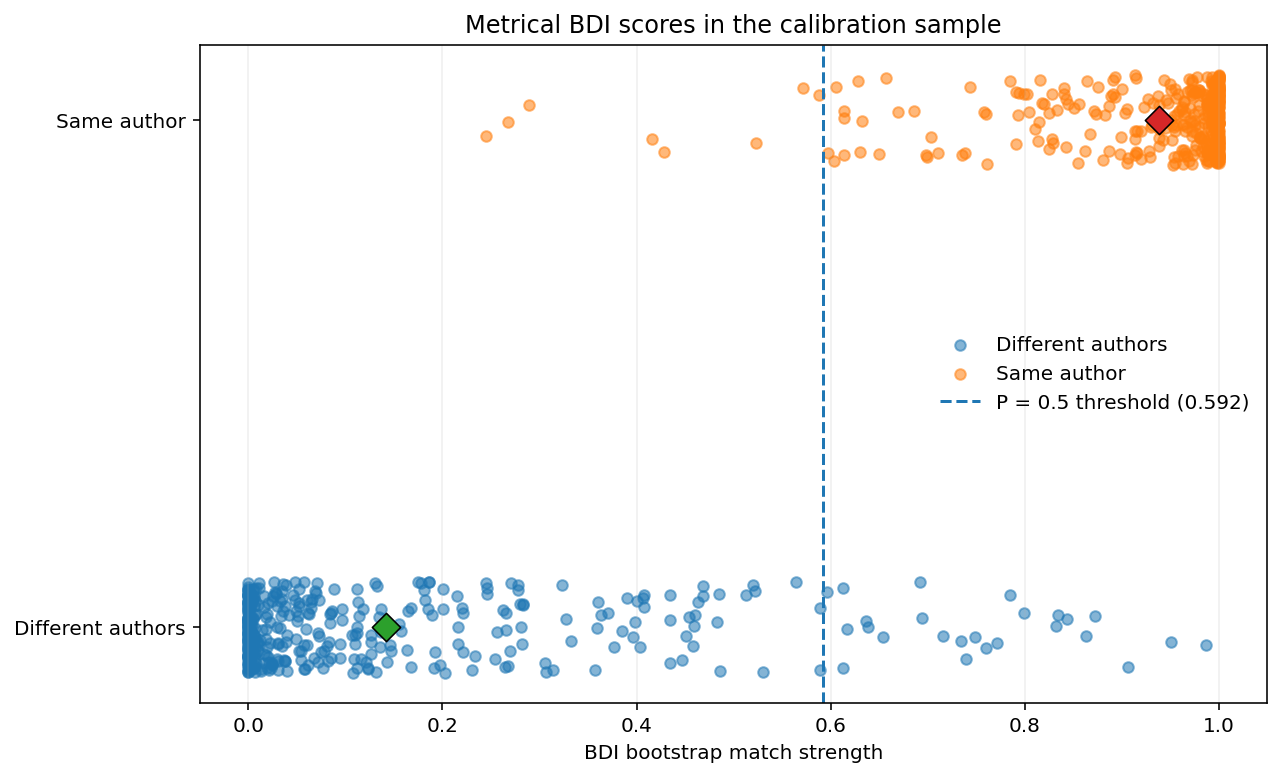

In [20]:
plot_rng = np.random.default_rng(42)

same_scores = calibration_df.loc[
    calibration_df["type"] == "same",
    "match_strength",
].to_numpy()

different_scores = calibration_df.loc[
    calibration_df["type"] == "different",
    "match_strength",
].to_numpy()

y_same = 1 + plot_rng.uniform(
    -0.09,
    0.09,
    size=len(same_scores),
)

y_different = 0 + plot_rng.uniform(
    -0.09,
    0.09,
    size=len(different_scores),
)

fig, ax = plt.subplots(
    figsize=(9, 5.5),
    dpi=144,
)

ax.scatter(
    different_scores,
    y_different,
    s=28,
    alpha=0.55,
    label="Different authors",
)

ax.scatter(
    same_scores,
    y_same,
    s=28,
    alpha=0.55,
    label="Same author",
)

if np.isfinite(threshold_match):
    ax.axvline(
        threshold_match,
        linestyle="--",
        linewidth=1.5,
        label=(
            f"P = 0.5 threshold "
            f"({threshold_match:.3f})"
        ),
    )

ax.scatter(
    different_scores.mean(),
    0,
    s=100,
    marker="D",
    edgecolor="black",
    linewidth=0.8,
    zorder=5,
)

ax.scatter(
    same_scores.mean(),
    1,
    s=100,
    marker="D",
    edgecolor="black",
    linewidth=0.8,
    zorder=5,
)

ax.set_yticks([0, 1])
ax.set_yticklabels(
    ["Different authors", "Same author"]
)

ax.set_xlabel("BDI bootstrap match strength")
ax.set_ylabel("")
ax.set_title(
    "Metrical BDI scores in the calibration sample"
)

ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

fig.savefig(
    BASE_DIR / "metrical_bdi_calibration.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    BASE_DIR / "metrical_bdi_calibration.pdf",
    bbox_inches="tight",
)

plt.show()


## Files produced

The notebook writes the following reusable files in the general hexameter `Metrical analysis` directory:

- `metrical_scaler.pkl`
- `metrical_label_encoder.pkl`
- `metrical_bdi_calibration_model.pkl`
- `metrical_bdi_calibration.csv`
- `metrical_bdi_calibration_with_probabilities.csv`
- `metrical_bdi_calibration.png`
- `metrical_bdi_calibration.pdf`

The four application notebooks load these objects and do not recalibrate the method.
